In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import cartopy
import cartopy.crs as ccrs

In [2]:
# Define directories, parameters
homepath = "/pscratch/sd/x/xueke/Github/"
u = "u"
v = "v"

lat_bnds_u = [20, 85]  
lon_bnds_reg = [-125, -105]   # SWNA
lat_bnds_reg = [30, 45]       # SWNA
width = lon_bnds_reg[1] - lon_bnds_reg[0]
height = lat_bnds_reg[1] - lat_bnds_reg[0]

# Define plot parameters
vmin = -12
vmax = 12
step = 25
levels = np.linspace(vmin, vmax, step)
colors = plt.cm.jet(np.linspace(0, 1, 77))
cmap = plt.cm.RdBu_r
cb_ylab = "Meridional wind speed (m/s)"
size = 16
labelsize = 14
fontsize = 7
titles = ["Wave 4", "Wave 5"]

# Fig. 2A: Meridional wind under wave-4 and wave-5 pattern

< GeoAxes: +proj=ortho +a=6378137.0 +lon_0=-120 +lat_0=90 +no_defs +type=crs >
< GeoAxes: +proj=ortho +a=6378137.0 +lon_0=-120 +lat_0=90 +no_defs +type=crs >


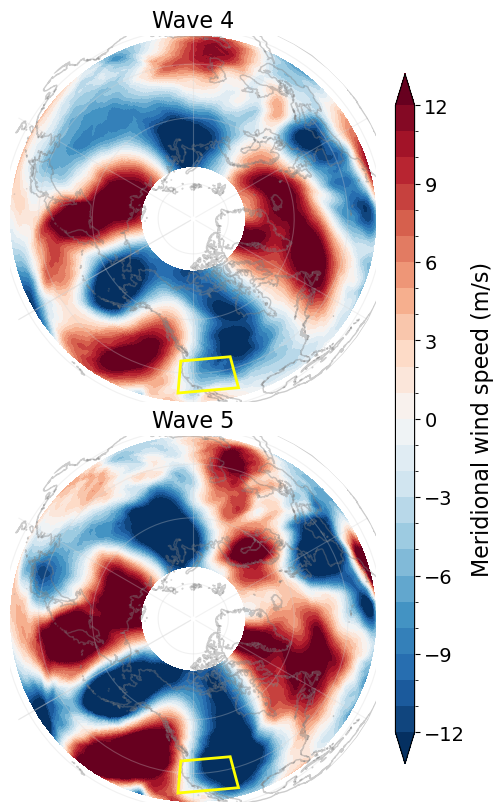

In [3]:
# Read in variables
v300_2026_wave4_timemean = xr.open_dataset(homepath + "data/v300_2026_wave4_timemean.nc")
v300_2026_wave5_timemean = xr.open_dataset(homepath + "data/v300_2026_wave5_timemean.nc")
v300_2026_timemean = [v300_2026_wave4_timemean[v], v300_2026_wave5_timemean[v]]

# Plot
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 8), layout="constrained", subplot_kw={'projection': ccrs.Orthographic(central_longitude=-120, central_latitude=90)})
for i in range(len(axes.flat)):
    ax = axes.flat[i]
    print(ax)
    ax.set_axis_off()
    p = v300_2026_timemean[i].plot(ax=ax, transform=ccrs.PlateCarree(), levels=levels, cmap=cmap, add_colorbar=False)
    ax.add_feature(cartopy.feature.LAND.with_scale('50m'), zorder = 8, facecolor='none', edgecolor='gray', alpha=0.4)
    ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False, color='lightgray', alpha=0.3, linestyle='-')
    ax.set_title(titles[i], size = size)
    ax.add_patch(mpatches.Rectangle(xy=[lon_bnds_reg[0], lat_bnds_reg[0]], width=width, height=height, facecolor='none', edgecolor='yellow',
                                    linewidth=2, alpha=1.0, zorder = 10, transform=ccrs.PlateCarree()))

cb = plt.colorbar(p, ax=axes.ravel().tolist(), shrink=0.9, pad=0.04, aspect=36)
cb.set_label(label=cb_ylab, size=size)    
cb.ax.tick_params(labelsize=labelsize)  

# Save plot
plt.savefig(homepath+'figures/Fig_2a.pdf', format='pdf', dpi=300, bbox_inches='tight')

# Fig 2B: Zonal mean zonal wind when wave 4 and wave 5 dominates

AxesSubplot(0.125,0.53;0.775x0.35)
AxesSubplot(0.125,0.11;0.775x0.35)


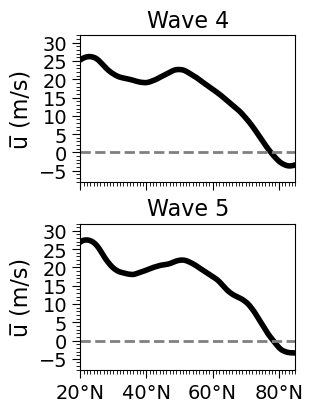

In [4]:
# Read in variables
u300_2026_wave4_zonalmean = xr.open_dataset(homepath + "data/u300_2026_wave4_zonalmean.nc")[u]
u300_2026_wave5_zonalmean = xr.open_dataset(homepath + "data/u300_2026_wave5_zonalmean.nc")[u]
u300_2026_zonalmean = [u300_2026_wave4_zonalmean, u300_2026_wave5_zonalmean]

# Plot
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(3, 4), layout="constrained", sharex=True)
for i in range(len(axes)):
    ax = axes[i]
    print(ax)

    u300_2026_zonalmean[i].plot(ax=ax, color='black', linewidth=4)

    # Plot settings
    xticks = np.arange(lat_bnds_u[0], lat_bnds_u[1], 20)
    xticklabels = [str(x) + u'\xb0' + 'N' for x in xticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)
    ax.tick_params('x',labelsize=labelsize)
    ax.tick_params('y',labelsize=labelsize)
    ax.set_xlabel('', size=size)
    ax.set_ylabel(u'u\u0305'+ ' (m/s)', size=size)
    ax.set_xlim([lat_bnds_u[0], lat_bnds_u[1]])
    ax.set_ylim([-8, 32])
    ax.tick_params(which='major', length=6) # width=2
    ax.tick_params(which='minor', length=3) # width=2
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
    ax.axhline(y=0, color='gray', linestyle='dashed', linewidth=2)
    ax.set_title(titles[i], size=size)

# Save plot 
plt.savefig(homepath+'figures/Fig_2b.pdf', format='pdf', dpi=600, bbox_inches='tight')

# Fig. 2C: Zonal mean zonal wind for March 2026 vs historical March climatology

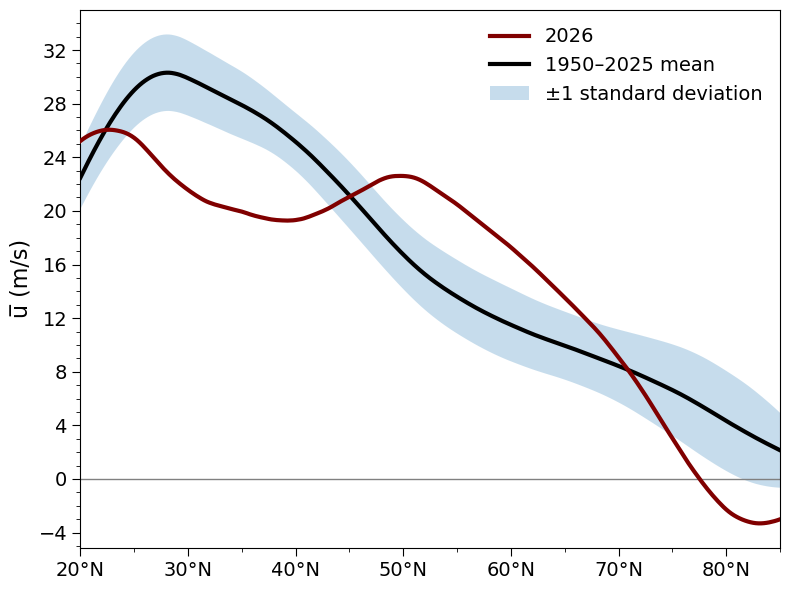

In [5]:
# Read in variables
u300_Mar_zonalmean_2026 = xr.open_dataset(homepath + "data/u300_Mar_zonalmean_2026.nc")[u]
u300_Mar_zonalmean_hist_mean = xr.open_dataset(homepath + "data/u300_Mar_zonalmean_hist_mean.nc")[u]
u300_Mar_zonalmean_hist_std = xr.open_dataset(homepath + "data/u300_Mar_zonalmean_hist_std.nc")[u]

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

u300_Mar_zonalmean_2026.plot(ax=ax, x='lat', color=colors[-1], linewidth=3, label='2026', zorder=6)             # 2026
u300_Mar_zonalmean_hist_mean.plot(ax=ax, x='lat', color='black', linewidth=3, label='1950–2025 mean', zorder=5) # 1950–2025 mean
ax.fill_between(u300_Mar_zonalmean_hist_mean.lat, u300_Mar_zonalmean_hist_mean - u300_Mar_zonalmean_hist_std, u300_Mar_zonalmean_hist_mean + u300_Mar_zonalmean_hist_std, 
                alpha=0.25, label=r'±1 standard deviation', zorder=2) # ±1 standard deviation

xticks = np.arange(lat_bnds_u[0], lat_bnds_u[1], 10)
xticklabels = [str(x) + u'\xb0' + 'N' for x in xticks]
ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels)
ax.tick_params('x',labelsize=labelsize)
ax.tick_params('y',labelsize=labelsize)
ax.set_xlabel('', size=size)
ax.set_ylabel(u'u\u0305'+ ' (m/s)', size=size)
ax.set_xlim([lat_bnds_u[0], lat_bnds_u[1]])
ax.tick_params(which='major', length=6) # width=2
ax.tick_params(which='minor', length=3) # width=2
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_major_locator(ticker.MultipleLocator(4))
ax.axhline(y=0, color='gray', linestyle='solid', linewidth=1)
ax.legend(ncol=1, fontsize=labelsize, frameon=False, columnspacing=0.4)
plt.title("", size=size) 
plt.tight_layout()

# Save plot
plt.savefig(homepath+'figures/Fig_2c.pdf', format='pdf', dpi=600, bbox_inches='tight')